<a href="https://colab.research.google.com/github/aunyarit2005-hash/Comparative-Performance-Analysis-of-Image-Classification-Models-for-Malaria-Infected-Red-Blood-Cells/blob/main/Preparedata_malalia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os

base_path = '/content/drive/MyDrive/Segment_malariae'
classes = ['normal', 'malaria']
target_folder = 'train'

def clean_mess():
    total_deleted = 0

    for class_name in classes:
        folder_path = os.path.join(base_path, class_name, target_folder)

        if not os.path.exists(folder_path):
            print(f"หาไม่เจอ: {folder_path} ข้าม")
            continue

        print(f"กำลังล้างในโฟลเดอร์: {class_name} ...")

        # กวาดไฟล์ทั้งหมดออกมา
        files = os.listdir(folder_path)

        count_class = 0
        for f in files:
            # เช็คว่าชื่อไฟล์มีคำว่า '_aug_' ไหม
            if '_aug_' in f:
                file_to_delete = os.path.join(folder_path, f)
                try:
                    os.remove(file_to_delete)
                    count_class += 1
                    total_deleted += 1
                except OSError as e:
                    print(f"ลบไม่ได้: {f} : {e}")

        print(f"ลบขยะใน {class_name} ไป {count_class} รูป")

        # เช็คยอดคงเหลือ
        remaining = len([name for name in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, name))])
        print(f"เหลือรูปจริง: {remaining} รูป (ควรจะเหลือเท่าเดิมคือประมาณ 500)")

    print(f"\nสรุป: ลบไปทั้งหมด {total_deleted} รูป สะอาดแล้ว")

# รันเลย
clean_mess()

หาไม่เจอ: /content/drive/MyDrive/Segment_malariae/normal/train ข้ามแม่ม
หาไม่เจอ: /content/drive/MyDrive/Segment_malariae/malaria/train ข้ามแม่ม

สรุป: ลบไปทั้งหมด 0 รูป สะอาดแล้วไอ้สัส!


In [ ]:
import os
from google.colab import drive

drive.mount('/content/drive')
# กำหนด Path หลักของโปรเจกต์
base_path = '/content/drive/MyDrive/Malaria_cell/Segment_Malariae'
classes = ['normal', 'malaria']
splits = ['train', 'val', 'test']

print(f"{'Split':<10} | {'Class':<10} | {'Count':<10}")
print("-" * 35)

total_images = 0

for s in splits:
    for c in classes:
        # ลองไล่ Path ตามโครงสร้าง: Segment_Malariae > class > split
        path = os.path.join(base_path, c, s)

        if os.path.exists(path):
            count = len([f for f in os.listdir(path) if os.path.isfile(os.path.join(path, f))])
            print(f"{s:<10} | {c:<10} | {count:<10}")
            total_images += count
        else:
            # กรณีสลับโครงสร้างเป็น: Segment_Malariae > split > class
            alt_path = os.path.join(base_path, s, c)
            if os.path.exists(alt_path):
                count = len([f for f in os.listdir(alt_path) if os.path.isfile(os.path.join(alt_path, f))])
                print(f"{s:<10} | {c:<10} | {count:<10}")
                total_images += count

print("-" * 35)
print(f"รวมทั้งหมด: {total_images} รูป")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Split      | Class      | Count     
-----------------------------------
-----------------------------------
รวมทั้งหมด: 0 รูป


In [ ]:
import os
import cv2
import albumentations as A
from tqdm import tqdm

base_path = '/content/drive/MyDrive/Malaria_cell/Segment_Malariae'
classes = ['normal', 'malaria']
target_folder = 'train'  # ทำเฉพาะ Train

# --- 2. กำหนดจำนวนรูปที่จะสร้างเพิ่ม ---
# 500 รูปเดิม + (4 รูปใหม่ x 500) = 2,500 รูป
AUG_FACTOR = 4

# --- 3. เทคนิค Augmentation (Medical Grade) ---
aug_pipeline = A.Compose([
    A.Resize(height=224, width=224),
    A.HorizontalFlip(p=0.5),        # พลิกซ้ายขวา
    A.VerticalFlip(p=0.5),          # พลิกบนล่าง
    A.Rotate(limit=180, p=0.7),     # หมุนอิสระ 180 องศา
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5), # ปรับแสง/คอนทราสต์
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=0, p=0.5) # ขยับๆ ซูมๆ นิดนึง
])

def run_augmentation():
    print(f"เริ่มงาน... เป้าหมายคือปั๊มรูปเพิ่ม {AUG_FACTOR} เท่า")

    for class_name in classes:
        folder_path = os.path.join(base_path, class_name, target_folder)

        if not os.path.exists(folder_path):
            print(f"❌ หาไม่เจอ: {folder_path} ข้าม")
            continue

        print(f"📂 กำลังลุยโฟลเดอร์: {class_name} ...")

        # กวาดไฟล์ทั้งหมดออกมา
        all_files = os.listdir(folder_path)

        # คัดแยก: เอาเฉพาะไฟล์รูป และ ต้องไม่ใช่ไฟล์ที่เคย Augment ไปแล้ว (_aug_)
        original_images = [
            f for f in all_files
            if f.lower().endswith(('.png', '.jpg', '.jpeg')) and '_aug_' not in f
        ]

        print(f"   เจอรูปต้นฉบับ {len(original_images)} รูป ")

        count_generated = 0

        for img_name in tqdm(original_images, desc=f"Augmenting {class_name}"):
            img_path = os.path.join(folder_path, img_name)

            # อ่านรูป
            image = cv2.imread(img_path)
            if image is None:
                continue
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) # แปลงเป็น RGB เพื่อเข้า Albumentations

            # ลูปสร้างภาพใหม่
            for i in range(AUG_FACTOR):
                # ตั้งชื่อไฟล์ใหม่: original_aug_1.jpg, original_aug_2.jpg ...
                filename_no_ext = os.path.splitext(img_name)[0]
                extension = os.path.splitext(img_name)[1]
                new_filename = f"{filename_no_ext}_aug_{i+1}{extension}"
                save_path = os.path.join(folder_path, new_filename)

                if os.path.exists(save_path):
                    continue

                try:
                    # เสกรูปใหม่
                    augmented = aug_pipeline(image=image)['image']
                    augmented = cv2.cvtColor(augmented, cv2.COLOR_RGB2BGR) # แปลงกลับเป็น BGR

                    # บันทึก
                    cv2.imwrite(save_path, augmented)
                    count_generated += 1

                except Exception as e:
                    print(f"พังตรงรูป {new_filename}: {e}")

        print(f"✅ จบ {class_name}: สร้างเพิ่มไป {count_generated} รูป\n")

    print("🎉 เสร็จหมดแล้ว")

# สั่งรัน
run_augmentation()

/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


เริ่มงาน... เป้าหมายคือปั๊มรูปเพิ่ม 4 เท่า
📂 กำลังลุยโฟลเดอร์: normal ...
   เจอรูปต้นฉบับ 300 รูป (พวกที่ Augment แล้วกูไม่นับนะ)


Augmenting normal: 100%|██████████| 300/300 [00:25<00:00, 11.67it/s]


✅ จบ normal: สร้างเพิ่มไป 1200 รูป

📂 กำลังลุยโฟลเดอร์: malaria ...
   เจอรูปต้นฉบับ 300 รูป (พวกที่ Augment แล้วกูไม่นับนะ)


Augmenting malaria: 100%|██████████| 300/300 [00:34<00:00,  8.58it/s]

✅ จบ malaria: สร้างเพิ่มไป 1200 รูป

🎉 เสร็จหมดแล้วโว้ย! ไปเช็คดู


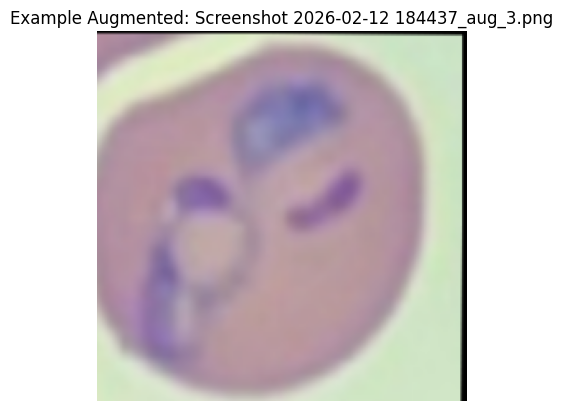

In [ ]:
import matplotlib.pyplot as plt
import glob
import random

def show_example(class_name='malaria'):
    folder = os.path.join(base_path, class_name, 'train')

    # หาไฟล์ที่ Augment แล้ว
    aug_files = glob.glob(os.path.join(folder, "*_aug_*"))

    if not aug_files:
        print("ยังไม่ได้ทำ Augmentation หรือหาไฟล์ไม่เจอ")
        return

    # สุ่มมา 1 รูป
    file_path = random.choice(aug_files)
    img = cv2.imread(file_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.imshow(img)
    plt.title(f"Example Augmented: {os.path.basename(file_path)}")
    plt.axis('off')
    plt.show()

# ลองกดรันดู
show_example()

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# --- ตั้งค่า ---
IMG_SIZE = (224, 224)  # MobileNet ชอบไซส์นี้
BATCH_SIZE = 32        # ยัดเข้าทีละ 32 รูป
base_path = '/content/drive/MyDrive/Segment_malariae/train'

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# --- โหลดรูปจากโฟลเดอร์ ---
print("กำลังโหลดรูป Train...")
train_generator = train_datagen.flow_from_directory(
    directory=os.path.join(base_dir, 'train'), # ชี้ไปที่โฟลเดอร์ train
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

print("กำลังโหลดรูป Validation...")

validation_generator = val_datagen.flow_from_directory(
    directory=os.path.join(base_dir, 'val'),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

กำลังโหลดรูป Train...


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Segment_malariae/train'

In [ ]:
folder_path = os.path.join(base_path, 'malaria', 'train')

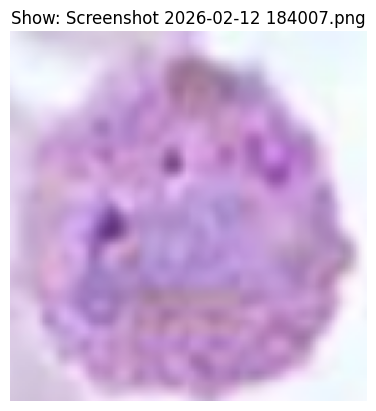

In [ ]:
import matplotlib.pyplot as plt
import os
import cv2
import random



def show_example(class_name='malaria'):
    folder = os.path.join('/content/drive/MyDrive/Malaria_cell/Segment_Malariae/', class_name, 'train')

    # 1. เช็คก่อนว่าโฟลเดอร์มีจริงไหม
    if not os.path.exists(folder):
        print(f"หาไม่เจอ: {folder} ")
        return

    # 2. กวาดชื่อไฟล์ทั้งหมดในโฟลเดอร์ออกมาก่อน
    all_files = os.listdir(folder)

    # 3. คัดเอาเฉพาะไฟล์รูป
    image_files = [f for f in all_files if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    if not image_files:
        print("ในโฟลเดอร์ไม่มีรูปเลย")
        return

    # 4. สุ่มชื่อไฟล์มาจาก list
    random_filename = random.choice(image_files)

    # 5. ต่อ Path ให้ครบ (Folder + Filename)
    full_path = os.path.join(folder, random_filename)

    # 6. อ่านรูป
    img = cv2.imread(full_path)
    if img is None:
        print(f"อ่านรูปไม่ได้: {full_path}")
        return

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # 7. แสดงผล
    plt.imshow(img)
    plt.title(f"Show: {random_filename}")
    plt.axis('off')
    plt.show()

# สั่งรัน
show_example()

In [ ]:
import matplotlib.pyplot as plt
import glob
import random

def show_example(class_name='malaria'):
    folder = os.path.join(base_path, class_name, 'train')

    # หาไฟล์ที่ Augment แล้ว
    aug_files = glob.glob(os.path.join(folder, "*_aug_*"))

    if not aug_files:
        print("ยังไม่ได้ทำ Augmentation หรือหาไฟล์ไม่เจอ")
        return

    # สุ่มมา 1 รูป
    file_path = random.choice(aug_files)
    img = cv2.imread(file_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.imshow(img)
    plt.title(f"Example Augmented: {os.path.basename(file_path)}")
    plt.axis('off')
    plt.show()

# ลองกดรันดู
show_example()

ยังไม่ได้ทำ Augmentation หรือหาไฟล์ไม่เจอ
